In [3]:
import pandas as pd
dataset=pd.read_csv("50_Startups.csv")
dataset=pd.get_dummies(dataset,drop_first=1)

In [4]:
dataset.columns

Index(['R&D Spend', 'Administration', 'Marketing Spend', 'Profit',
       'State_Florida', 'State_New York'],
      dtype='str')

In [5]:
independent=dataset[['R&D Spend', 'Administration', 'Marketing Spend','State_Florida', 'State_New York']]
dependent=dataset[['Profit']]

In [32]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(independent,dependent,test_size=0.18,random_state=0)

In [111]:
from sklearn.tree import DecisionTreeRegressor
regressor=DecisionTreeRegressor(criterion='squared_error',splitter='best')
regressor=regressor.fit(X_train,y_train)
y_pred=regressor.predict(X_test)

In [112]:
from sklearn.metrics import r2_score
r_score=r2_score(y_test,y_pred)
r_score

0.9802100603788755

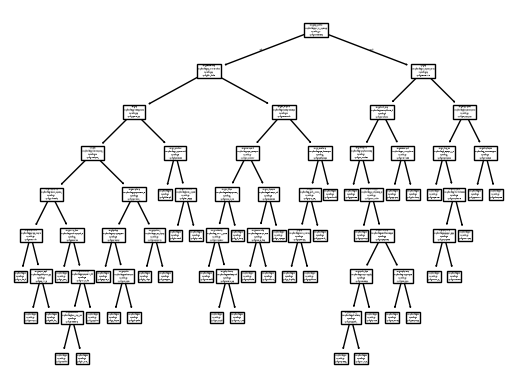

In [108]:
import matplotlib.pyplot as plt
from sklearn import tree
tree.plot_tree(regressor)
plt.show()

In [113]:
import pickle
filename="Decision_Tree_best_model.sav"
pickle.dump(regressor,open(filename,'wb'))
loaded_model=pickle.load(open("Decision_Tree_best_model.sav",'rb'))